# Automated Bayesian model comparison

This notebook will demonstrate how easy it is to perform Bayesian model comparison (BMC) in a principled way. As a running example, we will use the UK soccer goals dataset used in the seminal paper by Hastie & Green (2012). While the models we compare can easily be implemented in bamojax (and they are, in some other example notebooks), we will also demonstrate how to parse a [Stan](https://mc-stan.org/) model into bamojax.

There are many ways one can implement BMC. We will show here:

- Explicitly computing the marginal likelihood of each model, and computing the Bayes factor for the comparison.
- Using reversible-jump to *sample* the models themselves. This approach is elegant but often very difficult to do. We show how our anchored RJSMC approach achieves this easily, without user-specified jump proposals.

In [53]:
%load_ext autoreload
%autoreload 2

import os

SELECTED_DEVICE = '6'
print(f'Setting CUDA visible devices to [{SELECTED_DEVICE}]')
os.environ['CUDA_VISIBLE_DEVICES'] = f'{SELECTED_DEVICE}'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setting CUDA visible devices to [6]


In [54]:
import matplotlib.pyplot as plt

import jax
jax.config.update("jax_enable_x64", True)

import jax.random as jrnd
import jax.numpy as jnp
import blackjax

import sys
import pandas as pd

import bamojax
from bamojax.samplers import mcmc_sampler
from bamojax.inference import SMCInference
from bamojax.model_search.anchored_rjsmc import RJSMCInference
from bamojax.utility.StanParser import stan_to_bamojax

print('Python version:     ', sys.version)
print('Jax version:        ', jax.__version__)
print('BlackJax version:   ', blackjax.__version__)
print('bamojax version:    ', bamojax.__version__)
print('Jax default backend:', jax.default_backend())
print('Jax devices:        ', jax.devices())

SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

def pretty_axis(ax, fix_xaxis=True, fix_yaxis=True):
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False) 
    if fix_xaxis:
        ax.spines['bottom'].set_position(('axes', -0.05))
    if fix_yaxis:
        ax.spines['left'].set_position(('axes', -0.05))

#

Python version:      3.11.15 (main, Mar  3 2026, 09:26:23) [GCC 11.4.0]
Jax version:         0.10.2
BlackJax version:    1.7.1
bamojax version:     0.4.4+0.gd04e854.dirty
Jax default backend: gpu
Jax devices:         [CudaDevice(id=0)]


## Data

Let us first load the data:

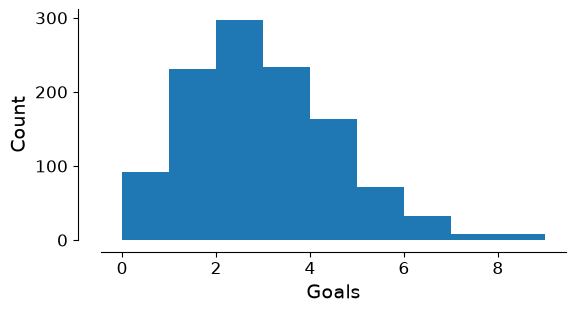

In [55]:
files = ['2005-06', '2006-07', '2007-08']
goals = []

for year in files:
    df = pd.read_csv(f'data/{year}.csv')  
    total_goals = df['FTHG'] + df['FTAG']
    total_goals_array = total_goals.to_numpy()
    goals.extend(total_goals_array)

Y = jnp.array(goals)

plt.figure(figsize=(6, 3))
ax = plt.gca()
ax.hist(Y, bins=jnp.arange(0, 10, 1))
ax.set_xlabel('Goals')
ax.set_ylabel('Count')
pretty_axis(ax)

## The models 
There are two models we wish to compare here, following the canonical example by Hastie & Green, a Poisson model:

$$
    \begin{align*}
        \lambda &\sim \text{Gamma}(\alpha, \beta) \\
        y_i & \sim \text{Poisson}(\lambda)
    \end{align*}
$$
and a negative binomial model:
$$
    \begin{align*}  
        \kappa &\sim \text{Gamma}(\alpha_\kappa, \beta_\kappa) \\
        \lambda &\sim \text{Gamma}(\alpha_\lambda, \beta_\lambda) \\
        y_i &\sim \text{NegBin}(\lambda, \kappa)
    \end{align*}
$$
The additional $\kappa$ parameter allows for _overdispersion_, that is, more variance than we would expect given the Poisson model (where $\text{var}(Y)=\lambda$).

We shall use _Stan_ implementations for these models, and parse them to bamojax models for further processing. Of course we could define the bamojax models directly, but this shows how you can use your existing Stan models in bamojax model comparison!

In [56]:
poisson_stan = """
data {
    int<lower=1> N;
    array[N] int<lower=0> Y;
}

parameters {
    real<lower=0> lambda;
}

model {
    // Prior
    lambda ~ gamma(25, 10);

    // Likelihood
    Y ~ poisson(lambda);
}
"""

negbin_stan = """
data {
    int<lower=1> N;
    array[N] int<lower=0> Y;
}

parameters {
    real<lower=0> lambda;
    real<lower=0> kappa;
}

model {
    // Priors
    lambda ~ gamma(25, 10);
    kappa ~ gamma(1, 10);

    // Likelihood
    Y ~ neg_binomial_2(lambda, 1.0 / kappa);
}
"""

data = dict(N = len(Y), Y = Y)

poisson_bamojax = stan_to_bamojax(poisson_stan, data)
negbin_bamojax = stan_to_bamojax(negbin_stan, data)

models = [poisson_bamojax, negbin_bamojax]

for model in models:
    print(model)

lambda     ~  Gamma(concentration=25, rate=10)
Y          ~  Poisson(f(lambda))

lambda     ~  Gamma(concentration=25, rate=10)
kappa      ~  Gamma(concentration=1, rate=10)
Y          ~  NegativeBinomial2(f(lambda, kappa))



# Analyses

## Posterior and marginal likelihood approximations

Now let us estimate the posteriors and marginal likelihoods of each model using sequential Monte Carlo, with adaptive Hamiltonian Monte Carlo mutations:

In [57]:
%%time
def smc_fit(key, model, num_particles = 1000, num_mutations = 2, num_chains = 1, mutator = blackjax.hmc):
    engine = SMCInference(model=model, num_particles=num_particles, num_mutations=num_mutations, num_chains=num_chains, mcmc_kernel=mcmc_sampler(model, mutator), adaptive=True)
    return jax.jit(engine.run)(key)

#
key = jrnd.PRNGKey(0)

fits = []

for model in models:
    key, subkey = jrnd.split(key)
    res = smc_fit(subkey, model)
    fits.append(res)
    print(res['lml'])



-2105.5556463675503
-2106.4637048662903
CPU times: user 7.21 s, sys: 277 ms, total: 7.49 s
Wall time: 7.35 s


In [58]:
def get_pmp(lmls):
    bf_10 = jnp.exp(lmls[0] - lmls[1])
    pmp_0 = bf_10 / (1 + bf_10)
    return pmp_0, 1-pmp_0

#
print(*get_pmp(lmls))

0.7126027071525933 0.28739729284740667


Note that we can compute the marginal likelihood exactly for the Poisson model, just to check the accuracy of the SMC estimate:

In [59]:
from jax.scipy.special import gammaln

def poisson_log_evidence(y, alpha=25.0, beta=10.0):
    y = jnp.asarray(y)
    N = len(y)
    S = jnp.sum(y)

    return alpha * jnp.log(beta) - gammaln(alpha) + gammaln(alpha + S) - (alpha + S) * jnp.log(beta + N) - jnp.sum(gammaln(y + 1))

#
exact_poisson_lml = poisson_log_evidence(Y, alpha=25, beta=10)
print(exact_poisson_lml)


-2105.500381039084


Pretty close!

## Anchored reversible-jump SMC

Reversible-jump is an elegant, but very difficult to use in practice, technique to sample _across_ different models. In theory, it gives us exactly what we want: posterior model probabilities, even if we have a collection of many models, potentially of different dimensionalities too. However, implementations require that we come up with _proposal distributions between models_, and there is no general way to do this. This means that for your specific use case, you have to come up with your own proposals and related mechanisms, which is difficult and time-consuming. For instance, Hastie & Green (2012) determine trans-dimensional jump proposals for the soccer goal data we used above. While that is great theoretically, if we would add another model we would be stuck. Furthermore, Hastie and Green note how sensitive the performance of reversible-jump MCMC is to slight changes to these proposals.

Recently, we have developed the solution to this problem. The idea has two key elements:

1. First, we use reversible-jump in SMC rather than MCMC. SMC has several favourable properties, especially for 'difficult' landscapes to sample from (see my tutorial paper, [Hinne, 2025](https://pubmed.ncbi.nlm.nih.gov/40138056/)).
2. Second, we use the particle representation of SMC __to determine the proposal distributions__. This is the crux; the particles that are _not_ sampling from the active model, represent the posterior of the _target_ model (we calls these particles _anchors_), and so via independent-Metropolis give a very useful proposal distribution!

Let's see the combined algorithm, [Anchored reversible-jump SMC (ARJSMC)](https://arxiv.org/abs/2610.09930v1) in action for the soccer example:

In [60]:
%%time
num_particles = 1000
kernels = [dict(mcmc_kernel=blackjax.normal_random_walk, mcmc_parameters=dict(sigma=0.15 * jnp.eye(int(m.get_model_size())))) for m in models]

engine = RJSMCInference(models, num_particles=2000, within_model_kernels=kernels, num_mutations=100)
key, subkey = jrnd.split(key)
res = engine.run(subkey)

CPU times: user 25.9 s, sys: 123 ms, total: 26 s
Wall time: 26 s


In [61]:
print(res['model_probs'])
print(res['lml_per_model'])

[0.704 0.296]
[-2105.50455787 -2106.37097678]


The results are virtually identical to the marginal-likelihood based approach. Note that the above took effectively zero model-specific choices (and even the mutation kernel could easily be replaced by a meaningful default). This is a unique contribution to reversible-jump Monte Carlo algorithms and suddenly makes this approach much more attractive!